# Matching and Weighting on Observables — Public Coverage and Employment

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 1-year PUMS (pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. It reads PUMS
through a client that returns **weighted cell counts and record counts only**: no person-level row is
read, printed or stored anywhere below.

The analysis was fixed in a **pre-analysis plan** (`pap/C05_pap.md`) committed before any table here was
retrieved. The notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Compare** people only with others who share the same measured characteristics, by stratifying on
   covariate cells and by weighting with a propensity score, and say what each estimate assumes.
2. **Check** that the adjustment worked, with standardised mean differences before and after weighting and a
   picture of the overlap between the groups.
3. **Fit** a propensity model to cells of counts, using frequency weights, and see why that equals fitting it to
   the people the cells stand for.
4. **Measure** how large a further hidden factor would have to be, with Rosenbaum bounds, and read the number Gamma
   next to the negative control instead of by itself.
5. **Run** a negative-control outcome that treatment cannot affect, as the one test available for an assumption
   that cannot itself be tested, and say what a failure of it means for every number above it.

## Prerequisites

**Knowledge.** Logistic regression; the idea of confounding; what a standardised mean difference is.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the
environment variable `CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in
`KRL_SECRETS_PATH`. The key is read at runtime and is never printed or written into this notebook's output.
The retrieval reads every state and takes several minutes; it waits and retries on HTTP 503.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package
(its `methods.matching` module holds the estimators).

**Prior notebooks.** C01 introduces the identification contract; C02 introduces the cells-only PUMS client.

## Data Provenance

| Item | Meaning | Role |
|---|---|---|
| `PUBCOV` | public health coverage recode | treatment |
| `ESR` | employment status recode | outcome (employed = 1 or 2) |
| `NATIVITY` | native or foreign born | negative-control outcome |
| `AGEP`, `SEX`, `SCHL`, `DIS`, `NP` | age, sex, education, disability, household size | covariates (age, education and household size in bands) |
| `POVPIP` | income-to-poverty ratio | sample restriction: below 200% of the poverty level |
| state's Medicaid expansion status | `data/policy/medicaid/expansion_dates.csv` | covariate (state is not in the cells; see below) |

Published labels for every variable are fetched from the Census variables endpoint and recorded in the
provenance files, with the SHA-256 of the pre-analysis plan.

> **Why not state.** Cells fine enough to hold the covariates above would fall mostly under the 10-record
> small-cell floor within any one state. The client therefore pools states **before** applying the floor, and
> this notebook carries the state's Medicaid expansion status instead. Other differences between states are an
> unmeasured confounder, which the sensitivity analysis addresses. The plan records this departure from the
> track specification before retrieval.

## Design and identification

**Estimand, as the plan states it.** Among adults aged 19 to 64 below 200% of the poverty level, the average effect on
the treated (ATT) of having public coverage on the probability of being employed, in percentage points.

**How to read the results.** The plan's own rule makes the estimates *descriptive associations* unless two checks
both pass. The cells below report whether they did. Every figure is therefore an **adjusted difference**: the
employment difference between people with and without public coverage who share the measured characteristics,
and an effect only if nothing unmeasured is left.

**Assumption.** Within a covariate cell, whether someone has public coverage is unrelated to their employment
potential. **This cannot be tested.** Balance on measured characteristics says nothing about unmeasured ones; the
negative control and the Rosenbaum Gamma say something about it, and the Gamma is read together with the negative control.

**The sample is selected on something the outcome moves.** The restriction to income below 200% of the poverty level
uses income, and employment raises income; people who are employed are less often below the line. That is a selection
on the outcome, and the design does not undo it.

**Decision rule, fixed in the plan.** No effect if the 95% interval of the stratified estimate contains zero.
Credible only if the negative-control outcome and the weighted balance check both pass; otherwise the estimates are
descriptive associations.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import matching
from krl_tutorials_data.sources import DataAccessError, fetch_acs_pums

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C05_public_coverage_matching"
PAP = NB_DIR / "pap" / "C05_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

YEAR = 2023
EXPANDED_BY = "2022-12-31"          # expanded on or before this date = expanded for a 2023 survey
GAMMAS = [1.0, 1.1, 1.2, 1.5, 2.0, 3.0]
SMD_LIMIT = 0.10
TARGET = "employed"
ADDED = "not pre-specified (added after review, 2026-10-23)"

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"vintage           : ACS {YEAR} 1-year PUMS")

pre-analysis plan : projects/09-causal-identification/C05_public_coverage_matching/pap/C05_pap.md
plan SHA-256      : 0146e53dc40ef43e70353a5f95e2cac4e739ca1a16f56ea046f20bf2d43cf55a
vintage           : ACS 2023 1-year PUMS


### Which states count as expanded

The state's expansion status comes from the repository's policy table. A state that expanded during 2023 is
neither: it is excluded and counted.

In [2]:
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")
policy["group"] = np.select(
    [policy["status"] == "Not Adopted",
     (policy["status"] == "Adopted") & (policy["expansion_effective"] <= EXPANDED_BY)],
    ["not expanded", "expanded"], default="excluded: expanded during 2023",
)
print(policy["group"].value_counts().to_string())

FIPS_URL = "https://www2.census.gov/geo/docs/reference/state.txt"
reply = requests.get(FIPS_URL, timeout=60, headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
fips = dict(zip(codes["STATE_NAME"], codes["STATE"]))
groups = {name: sorted(fips[s] for s in policy.loc[policy["group"] == name, "state"])
          for name in ("expanded", "not expanded")}
print({name: len(v) for name, v in groups.items()}, "states pooled in each group")
print(policy.loc[policy["state"] == "Wisconsin", ["state", "status", "group"]].to_string(index=False), "(Wisconsin covers adults to 100% of the poverty level through its own programme, as recalled and not verified in this build)")

group
expanded                          39
not expanded                      10
excluded: expanded during 2023     2
{'expanded': 39, 'not expanded': 10} states pooled in each group
    state      status        group
Wisconsin Not Adopted not expanded (Wisconsin covers adults to 100% of the poverty level through its own programme, as recalled and not verified in this build)


### Retrieving the cells

Two pooled requests, one for each expansion group. Each reads every state in turn, restricts the records to adults
below 200% of the poverty level, bands age, education, household size and employment status, sums whole cells
across states, and only then withholds cells of fewer than 10 records.

In [3]:
for attempt in range(4):
    try:
        published = requests.get(
            f"https://api.census.gov/data/{YEAR}/acs/acs1/pums/variables.json", timeout=180
        ).json()["variables"]
        break
    except requests.RequestException:
        clock.sleep(10 * (attempt + 1))
else:
    raise SystemExit("The Census variables list could not be read.")

CODES = ("AGEP", "SEX", "SCHL", "DIS", "NP", "PUBCOV", "ESR", "NATIVITY", "POVPIP")
VARIABLES = {code: published[code]["label"] for code in CODES}
AGGREGATE = ["AGEP", "SEX", "SCHL", "DIS", "NP", "PUBCOV", "ESR", "NATIVITY"]
KEEP = {"AGEP": (19, 64), "POVPIP": (0, 199)}
BANDS = {
    "AGEP": [19, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    "SCHL": [0, 16, 18, 21, 25],
    "NP": [1, 2, 3, 4, 6, 21],
    "ESR": [0, 1, 3, 4, 6, 7],
}

pulls = []
try:
    for name, state_codes in groups.items():
        frame, prov = fetch_acs_pums(
            year=YEAR, variables=VARIABLES, aggregate_by=AGGREGATE,
            geography=[f"state:{c}" for c in state_codes], keep=KEEP, bands=BANDS,
        )
        frame["expanded"] = int(name == "expanded")
        pulls.append(frame)
        prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c05_pums{YEAR}_{name.replace(' ', '_')}.json")
        a = frame.attrs
        print(f"{name:13s}: {len(state_codes)} states; records read {a['records_read']:>9,}, kept {a['records_kept']:>8,}; "
              f"cells {len(frame):>5,}; withheld {a['suppressed_records']:>6,} records "
              f"({a['suppressed_records'] / a['records_kept']:.1%})")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise
raw_cells = pd.concat(pulls, ignore_index=True)

expanded     : 39 states; records read   289,644, kept  289,644; cells 4,207; withheld 13,630 records (4.7%)
not expanded : 10 states; records read   127,033, kept  127,033; cells 2,566; withheld 13,973 records (11.0%)


### The restriction count

The service now applies the age and poverty ranges before it sends records, so the pull above cannot say how many
records the restriction removed. Two more pulls count them: all records in the file, and those aged 19 to 64.

In [4]:
"""The restriction count the server-side filter hides: records in the file, aged 19-64, and kept."""
def pull(tag, aggregate_by, keep=KEEP, bands=BANDS, codes=CODES):
    """Cells for both expansion groups; one provenance record per group, bound to the plan."""
    frames, infos = [], []
    bands = {k: v for k, v in bands.items() if k in codes and k in aggregate_by} if bands else bands
    for name, state_codes in groups.items():
        frame_, prov_ = fetch_acs_pums(
            year=YEAR, variables={c: VARIABLES[c] for c in codes}, aggregate_by=aggregate_by,
            geography=[f"state:{c}" for c in state_codes], keep=keep, bands=bands)
        frame_["expanded"] = int(name == "expanded")
        frames.append(frame_)
        infos.append(dict(frame_.attrs))
        prov_.with_pap(PAP).write(NB_DIR / "provenance" / f"c05_pums{YEAR}_{tag}_{name.replace(' ', '_')}.json")
    return pd.concat(frames, ignore_index=True), infos

try:
    _, in_file = pull("records_in_file", ["AGEP"], keep=None, bands={"AGEP": [0, 200]}, codes=("AGEP",))
    _, aged = pull("records_aged_19_64", ["AGEP"], keep={"AGEP": (19, 64)}, bands={"AGEP": [0, 200]}, codes=("AGEP",))
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  detail : {exc}")
    raise
restriction = pd.DataFrame({
    "group": list(groups), "records in the file": [i["records_read"] for i in in_file],
    "aged 19-64": [i["records_read"] for i in aged], "and below 200% of poverty (kept)": [p.attrs["records_kept"] for p in pulls]})
restriction["share kept of the file"] = restriction["and below 200% of poverty (kept)"] / restriction["records in the file"]
print(restriction.to_string(index=False, formatters={"share kept of the file": "{:.1%}".format}))
print("the service applies the age and poverty ranges before sending records, so the main pull cannot report how many it excluded; these two pulls do.")

       group  records in the file  aged 19-64  and below 200% of poverty (kept) share kept of the file
    expanded              2344164     1331875                            289644                  12.4%
not expanded               940248      529058                            127033                  13.5%
the service applies the age and poverty ranges before sending records, so the main pull cannot report how many it excluded; these two pulls do.


In [5]:
"""From cells to one row per covariate cell and treatment group."""
cells = raw_cells[raw_cells["ESR"].isin([1, 3, 6])].copy()
dropped = raw_cells.loc[~raw_cells["ESR"].isin([1, 3, 6]), "n_records"].sum()
print(f"records in dropped employment categories (armed forces or not applicable): {int(dropped):,}")

cells["treated"] = (cells["PUBCOV"] == 1).astype(int)
cells["employed"] = (cells["ESR"] == 1).astype(int)
assert cells[TARGET].var() > 0, "the outcome must vary"
cells["foreign"] = (cells["NATIVITY"] == 2).astype(int)
for tag, weight in (("", "n_records"), ("w_", "weighted_n")):
    cells[f"{tag}n"] = cells[weight]
    cells[f"{tag}e"] = cells[weight] * cells["employed"]
    cells[f"{tag}f"] = cells[weight] * cells["foreign"]

KEY = ["AGEP", "SEX", "SCHL", "DIS", "NP", "expanded"]
SUMS = ["n", "e", "f", "w_n", "w_e", "w_f"]
by_group = cells.groupby(KEY + ["treated"])[SUMS].sum().reset_index()
wide = by_group.pivot(index=KEY, columns="treated", values=SUMS).fillna(0.0)
wide.columns = [f"{name}{int(flag)}" for name, flag in wide.columns]
wide = wide.reset_index()
both = (wide["n1"] > 0) & (wide["n0"] > 0)

print(f"covariate cells        : {len(wide):,}; with both groups present: {int(both.sum()):,}")
print(f"records                : treated {int(wide['n1'].sum()):,}, untreated {int(wide['n0'].sum()):,}")
print(f"share of treated records in cells with both groups: {wide.loc[both, 'n1'].sum() / wide['n1'].sum():.1%}")

records in dropped employment categories (armed forces or not applicable): 474
covariate cells        : 1,336; with both groups present: 1,063
records                : treated 179,351, untreated 209,249
share of treated records in cells with both groups: 95.7%


In [6]:
"""The unadjusted comparison."""
rate1 = 100 * wide["e1"].sum() / wide["n1"].sum()
rate0 = 100 * wide["e0"].sum() / wide["n0"].sum()
naive = rate1 - rate0
print(f"employment rate, public coverage    : {rate1:.2f}%")
print(f"employment rate, no public coverage : {rate0:.2f}%")
print(f"naive difference                    : {naive:+.2f} percentage points")

employment rate, public coverage    : 37.72%
employment rate, no public coverage : 67.11%
naive difference                    : -29.39 percentage points


### Estimate 1 (headline): stratify on the covariate cells (an adjusted difference)

Within each cell, compare the employment rate of the treated with that of the untreated, then average with weights
equal to each cell's treated count. A cell with no untreated record has no comparison and is dropped, and the share of
treated records that survives is printed.

In [7]:
"""Stratified adjusted difference on record counts, and the same on weighted population counts."""
used = wide[both]
strat = matching.stratified_effect(wide["e1"], wide["n1"], wide["e0"], wide["n0"])
est_s, se_s = 100 * strat.estimate, 100 * strat.se
ci_s = (est_s - 1.96 * se_s, est_s + 1.96 * se_s)
pop = matching.stratified_effect(wide["w_e1"], wide["w_n1"], wide["w_e0"], wide["w_n0"])
pre = matching.stratified_effect(used["e1"], used["n1"], used["e0"], used["n0"])
print(f"stratified adjusted difference (record counts): {est_s:+.2f} pp (SE {se_s:.2f}), 95% interval [{ci_s[0]:+.2f}, {ci_s[1]:+.2f}]")
print(f"cells used / dropped for lack of a comparison group: {strat.n_strata_used} / {strat.n_strata_dropped}; share of treated records kept {strat.share_treated_used:.1%}")
print(f"it describes the treated records in cells that hold both groups (the overlap); the standard error is conditional on the cell composition and ignores households")
print(f"the same estimate when the one-group cells are removed first: {100 * pre.estimate:+.2f} pp (identical: {abs(pre.estimate - strat.estimate) < 1e-12})")
print(f"population-weighted: {100 * pop.estimate:+.2f} pp (no standard error: the weights carry no sampling record); "
      f"the record-count figure is a statement about this sample's composition, the population-weighted one about the people the sample stands for")

stratified adjusted difference (record counts): -21.67 pp (SE 0.19), 95% interval [-22.05, -21.29]
cells used / dropped for lack of a comparison group: 1063 / 273; share of treated records kept 95.7%
it describes the treated records in cells that hold both groups (the overlap); the standard error is conditional on the cell composition and ignores households
the same estimate when the one-group cells are removed first: -21.67 pp (identical: True)
population-weighted: -20.71 pp (no standard error: the weights carry no sampling record); the record-count figure is a statement about this sample's composition, the population-weighted one about the people the sample stands for


### Estimate 2: weight with the propensity score

A main-effects logistic model of treatment on the covariate dummies, fitted to the **cell rows** with each cell's
record count as a frequency weight. A row standing for *n* people gives the same fit as *n* copies of it, which the
test suite checks. Untreated cells are then weighted by the odds of treatment.

In [8]:
"""Propensity model on cell rows with frequency weights."""
def design(frame: pd.DataFrame) -> tuple[np.ndarray, list[str]]:
    """Dummy-coded covariates of the cells, in a fixed order."""
    columns, names = [], []
    for variable, label in (("AGEP", "age"), ("SCHL", "education"), ("NP", "household size")):
        levels = sorted(frame[variable].unique())
        for level in levels[1:]:
            columns.append((frame[variable] == level).to_numpy(dtype=float))
            names.append(f"{label} {int(level)}")
    for variable, level, label in (("SEX", 2, "female"), ("DIS", 1, "disability"), ("expanded", 1, "expansion state")):
        columns.append((frame[variable] == level).to_numpy(dtype=float))
        names.append(label)
    return np.column_stack(columns), names


X_cell, names = design(wide)
rows = pd.concat([wide.assign(d=1, n=wide["n1"], e=wide["e1"], wn=wide["w_n1"], we=wide["w_e1"]),
                  wide.assign(d=0, n=wide["n0"], e=wide["e0"], wn=wide["w_n0"], we=wide["w_e0"])], ignore_index=True)
X_rows = np.vstack([X_cell, X_cell])
fit = matching.logit_propensity(X_rows, rows["d"].to_numpy(), frequency=rows["n"].to_numpy())
score = fit.propensity
print(f"covariate dummies in the model: {len(names)}; Newton iterations: {fit.n_iter}")
print(f"propensity range over cells: {score.min():.3f} to {score.max():.3f}")

# outcome rows: employed and not employed, each with its own frequency
def outcome_rows(freq_n: str, freq_e: str, p: np.ndarray):
    """Long rows (outcome, treatment, propensity, frequency) from cell counts."""
    d = rows["d"].to_numpy()
    y = np.concatenate([np.ones(len(rows)), np.zeros(len(rows))])
    dd = np.concatenate([d, d])
    pp = np.concatenate([p, p])
    ff = np.concatenate([rows[freq_e].to_numpy(), (rows[freq_n] - rows[freq_e]).to_numpy()])
    return y, dd, pp, ff


y_l, d_l, p_l, f_l = outcome_rows("n", "e", score)
ipw = matching.ipw_effect(y_l, d_l, p_l, estimand="att", frequency=f_l)
ipw_trim = matching.ipw_effect(y_l, d_l, p_l, estimand="att", frequency=f_l, trim=(0.05, 0.95))
est_i, se_i = 100 * ipw.estimate, 100 * ipw.se
est_t, se_t = 100 * ipw_trim.estimate, 100 * ipw_trim.se
fit_w = matching.logit_propensity(X_rows, rows["d"].to_numpy(), frequency=rows["wn"].to_numpy())
y_w, d_w, p_w, f_w = outcome_rows("wn", "we", fit_w.propensity)
ipw_pop = matching.ipw_effect(y_w, d_w, p_w, estimand="att", frequency=f_w)
print(f"IPW adjusted difference (ATT weights), no trimming     : {est_i:+.2f} pp (SE {se_i:.2f}), 95% interval [{est_i - 1.96 * se_i:+.2f}, {est_i + 1.96 * se_i:+.2f}]")
print(f"IPW ATT, trimmed to [.05,.95]: {est_t:+.2f} pp (SE {se_t:.2f}); records trimmed {ipw_trim.n_trimmed:,} of {int(rows['n'].sum()):,}")
print(f"IPW ATT, population-weighted : {100 * ipw_pop.estimate:+.2f} pp")
print(f"IPW treats every treated record, including the {1 - strat.share_treated_used:.1%} in cells with no untreated record, where the stratified estimate does not; the two targets differ")
print(f"propensity scores lie between {score.min():.3f} and {score.max():.3f}: "
      f"{'inside' if score.min() >= 0.05 and score.max() <= 0.95 else 'not inside'} [0.05, 0.95], so trimming removed {ipw_trim.n_trimmed:,} records "
      f"({'a no-op' if ipw_trim.n_trimmed == 0 else 'not a no-op'})")

covariate dummies in the model: 18; Newton iterations: 6
propensity range over cells: 0.055 to 0.920
IPW adjusted difference (ATT weights), no trimming     : -24.10 pp (SE 0.22), 95% interval [-24.53, -23.68]
IPW ATT, trimmed to [.05,.95]: -24.10 pp (SE 0.22); records trimmed 0 of 388,600
IPW ATT, population-weighted : -23.07 pp
IPW treats every treated record, including the 4.3% in cells with no untreated record, where the stratified estimate does not; the two targets differ
propensity scores lie between 0.055 and 0.920: inside [0.05, 0.95], so trimming removed 0 records (a no-op)


### Did the weighting balance what was measured?

Standardised mean differences for every covariate dummy, before and after weighting, and the overlap of the
propensity score between the groups. Overlap is the other half of the argument: weights cannot compare people who
have no counterpart.

       covariate  before  after
      disability   0.698  0.012
 expansion state   0.460 -0.015
    education 21  -0.309  0.002
          age 60   0.163 -0.016
    education 16   0.143 -0.025
          age 55   0.117  0.024
household size 2  -0.115 -0.018
          female   0.088 -0.035
          age 25  -0.081 -0.010
household size 4  -0.081 -0.043
          age 50   0.053  0.019
    education 18  -0.034 -0.037
household size 3  -0.031 -0.017
          age 45   0.007  0.019
          age 35  -0.005  0.006
household size 6   0.005 -0.000
          age 30  -0.003  0.001
          age 40  -0.003  0.007
largest absolute SMD: before 0.698, after 0.043


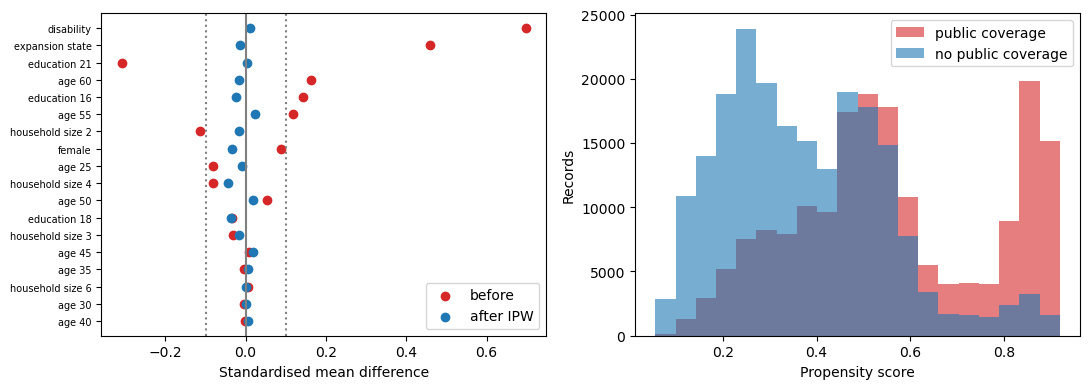

common support of the score: 0.055 to 0.920
 score bin from   to  treated records  untreated records
           0.06 0.10              143               2870
           0.10 0.14             1275              10874
           0.14 0.18             2951              13986
           0.18 0.23             5210              18828
           0.23 0.27             7530              23892
           0.27 0.31             8236              19681
           0.31 0.36             7925              16314
           0.36 0.40            10117              15177
           0.40 0.44             9657              12962
           0.44 0.49            17402              18972
           0.49 0.53            18791              17789
           0.53 0.57            17805              14846
           0.57 0.62            10782               7774
           0.62 0.66             5476               3420
           0.66 0.70             4017               1663
           0.70 0.75             4122       

In [9]:
"""Balance and overlap."""
d_rows = rows["d"].to_numpy()
adjust = np.where(d_rows == 1, 1.0, score / (1.0 - score))
before = matching.balance_table(X_rows, d_rows, names=names, frequency=rows["n"].to_numpy())
after = matching.balance_table(X_rows, d_rows, names=names, weights=adjust, frequency=rows["n"].to_numpy())
balance = pd.DataFrame({"covariate": names, "before": [r.smd for r in before], "after": [r.smd for r in after]})
balance["abs_before"] = balance["before"].abs()
balance = balance.sort_values("abs_before", ascending=False).drop(columns="abs_before")
print(balance.round(3).to_string(index=False))
max_after = float(balance["after"].abs().max())
print(f"largest absolute SMD: before {balance['before'].abs().max():.3f}, after {max_after:.3f}")

overlap = matching.overlap_data(score, d_rows, bins=20, frequency=rows["n"].to_numpy())
mid = 0.5 * (overlap.edges[:-1] + overlap.edges[1:])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = balance.iloc[::-1]
axes[0].scatter(order["before"], range(len(order)), color="tab:red", label="before")
axes[0].scatter(order["after"], range(len(order)), color="tab:blue", label="after IPW")
axes[0].axvline(0, color="grey")
axes[0].axvline(SMD_LIMIT, color="grey", linestyle=":")
axes[0].axvline(-SMD_LIMIT, color="grey", linestyle=":")
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order["covariate"], fontsize=7)
axes[0].set_xlabel("Standardised mean difference")
axes[0].legend()
width = overlap.edges[1] - overlap.edges[0]
axes[1].bar(mid, overlap.counts_treated, width=width, alpha=0.6, color="tab:red", label="public coverage")
axes[1].bar(mid, overlap.counts_control, width=width, alpha=0.6, color="tab:blue", label="no public coverage")
axes[1].set_xlabel("Propensity score")
axes[1].set_ylabel("Records")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"common support of the score: {overlap.common_support[0]:.3f} to {overlap.common_support[1]:.3f}")
overlap_table = pd.DataFrame({"score bin from": overlap.edges[:-1].round(2), "to": overlap.edges[1:].round(2),
                              "treated records": overlap.counts_treated, "untreated records": overlap.counts_control})
print(overlap_table.to_string(index=False))

In [10]:
"""Falsification 1: a negative-control outcome that public coverage cannot change."""
neg = matching.stratified_effect(used["f1"], used["n1"], used["f0"], used["n0"])
est_n, se_n = 100 * neg.estimate, 100 * neg.se
ci_n = (est_n - 1.96 * se_n, est_n + 1.96 * se_n)
NEG_PASS = ci_n[0] <= 0.0 <= ci_n[1]
print(f"FALSIFICATION: negative-control outcome, share foreign born | statistic={est_n:.3f} | adjusted difference in pp, 95% interval [{ci_n[0]:+.3f}, {ci_n[1]:+.3f}] | verdict={'PASS' if NEG_PASS else 'FAIL'}")

FALSIFICATION: negative-control outcome, share foreign born | statistic=-4.998 | adjusted difference in pp, 95% interval [-5.208, -4.788] | verdict=FAIL


In [11]:
"""Falsification 2: balance after weighting."""
BAL_PASS = max_after <= SMD_LIMIT
print(f"FALSIFICATION: covariate balance after IPW weighting | statistic={max_after:.4f} | largest absolute SMD, limit {SMD_LIMIT:.2f} | verdict={'PASS' if BAL_PASS else 'FAIL'}")

FALSIFICATION: covariate balance after IPW weighting | statistic=0.0431 | largest absolute SMD, limit 0.10 | verdict=PASS


### How much hidden bias could the estimate survive?

Rosenbaum bounds for a stratified binary outcome. Read them with the negative control above, not alone. Gamma is the factor by which an unmeasured characteristic could
multiply the odds of public coverage between two people in the same cell. At Gamma = 1 there is no hidden bias. The
worst-case p-value grows with Gamma; the headline is the Gamma at which it crosses 0.025 (a two-sided 0.05).

In [12]:
"""Rosenbaum bounds on the covariate cells, record counts."""
args = (used["e1"].astype(int), used["n1"].astype(int), used["e0"].astype(int), used["n0"].astype(int))
table = []
for g in GAMMAS:
    b = matching.rosenbaum_bounds(*args, gamma=g)
    table.append({"Gamma": g, "worst-case one-sided p": b.p_upper if est_s >= 0 else b.p_below_upper})
bounds = pd.DataFrame(table)
print(bounds.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
if (bounds["worst-case one-sided p"] == 0).any():
    print("a p-value shown as 0 is below the smallest positive number the computer can hold (about 1e-308).")
critical = matching.rosenbaum_critical_gamma(*args, alpha=0.025, gamma_max=100.0)
if critical == 1.0:
    print("The association does not survive hidden bias: even at Gamma = 1.0 the worst-case p-value exceeds 0.025.")
elif np.isinf(critical):
    print("The association survives hidden bias at every Gamma up to the largest tried, 100.")
else:
    print(f"Gamma = {critical:.2f} is the factor by which an unmeasured characteristic would have to multiply the odds of public "
          "coverage between two people in the same cell for the worst-case p-value to pass 0.025, on record counts that ignore the survey design.")
if not NEG_PASS:
    print("The negative control failed, so the covariate cells do not remove all the confounding that coverage and the outcome share: "
          "Gamma = 1, no hidden bias, is already contradicted by the data. Gamma then says how large a further hidden factor would have to be "
          "to account for a difference of this size, on record counts; it does not say whether coverage changes employment.")

 Gamma  worst-case one-sided p
     1                       0
   1.1                       0
   1.2                       0
   1.5                       0
     2               5.19e-118
     3                       1
a p-value shown as 0 is below the smallest positive number the computer can hold (about 1e-308).


Gamma = 2.36 is the factor by which an unmeasured characteristic would have to multiply the odds of public coverage between two people in the same cell for the worst-case p-value to pass 0.025, on record counts that ignore the survey design.
The negative control failed, so the covariate cells do not remove all the confounding that coverage and the outcome share: Gamma = 1, no hidden bias, is already contradicted by the data. Gamma then says how large a further hidden factor would have to be to account for a difference of this size, on record counts; it does not say whether coverage changes employment.


In [13]:
"""The estimates side by side, and the decision rule from the plan, applied as written."""
side = pd.DataFrame([
    {"estimate": "naive difference", "pp": naive, "se": np.nan},
    {"estimate": "stratified adjusted difference, record counts (plan's headline; overlap cells)", "pp": est_s, "se": se_s},
    {"estimate": "IPW adjusted difference, record counts (all treated records)", "pp": est_i, "se": se_i},
    {"estimate": "IPW, trimmed", "pp": est_t, "se": se_t},
    {"estimate": "stratified, population-weighted", "pp": 100 * pop.estimate, "se": np.nan},
    {"estimate": "IPW, population-weighted", "pp": 100 * ipw_pop.estimate, "se": np.nan},
])
print(side.round(2).to_string(index=False))
print()
null = ci_s[0] <= 0.0 <= ci_s[1]
print(f"Headline: {est_s:+.2f} pp (95% interval [{ci_s[0]:+.2f}, {ci_s[1]:+.2f}]); adjustment moved the naive {naive:+.2f} by {est_s - naive:+.2f}.")
print(f"The headline interval {'contains' if null else 'excludes'} zero: the adjusted difference is "
      f"{'not distinguishable from zero' if null else 'distinguishable from zero'}.")
print(f"Negative control passed: {NEG_PASS}; balance passed: {BAL_PASS}.")
if NEG_PASS and BAL_PASS:
    print("Both checks pass: by the plan's rule the adjusted difference is credible, conditional on no unmeasured confounding.")
else:
    print("At least one check fails: by the plan's rule these are descriptive associations, not identified effects.")
if not NEG_PASS:
    print(f"The negative control is the check that failed: after adjustment the share foreign born differs between the groups by {est_n:+.2f} pp "
          f"(95% interval [{ci_n[0]:+.2f}, {ci_n[1]:+.2f}]), a difference public coverage cannot produce.")

                                                                      estimate     pp   se
                                                              naive difference -29.39  NaN
stratified adjusted difference, record counts (plan's headline; overlap cells) -21.67 0.19
                  IPW adjusted difference, record counts (all treated records) -24.10 0.22
                                                                  IPW, trimmed -24.10 0.22
                                               stratified, population-weighted -20.71  NaN
                                                      IPW, population-weighted -23.07  NaN

Headline: -21.67 pp (95% interval [-22.05, -21.29]); adjustment moved the naive -29.39 by +7.72.
The headline interval excludes zero: the adjusted difference is distinguishable from zero.
Negative control passed: False; balance passed: True.
At least one check fails: by the plan's rule these are descriptive associations, not identified effects.
The negative co

## Added after review (2026-10-23)

Everything from here to the Limitations is **not pre-specified (added after review, 2026-10-23)**. The plan's primary
results are the ones above; none of these analyses replaces one. They answer questions the review raised about
what the withheld cells hide, whether the two estimators cover the same people, why the negative control failed, and
how to read Gamma.

In [14]:
"""not pre-specified (added after review, 2026-10-23): what the withheld cells hide, by treatment and outcome."""
print(ADDED)
margin_frame, margin_info = pull("margins", ["PUBCOV", "ESR", "NATIVITY"])
print(f"records withheld in the margin pull itself (cells of fewer than 10): {sum(i['suppressed_records'] for i in margin_info):,} of {sum(i['records_kept'] for i in margin_info):,}")
mf = margin_frame[margin_frame["ESR"].isin([1, 3, 6])].copy()
mf["treated"], mf["employed"] = (mf["PUBCOV"] == 1).astype(int), (mf["ESR"] == 1).astype(int)
full = mf.groupby(["treated", "employed"])["n_records"].sum()
kept = cells.groupby(["treated", "employed"])["n_records"].sum()
margin = pd.DataFrame({"in the file": full, "in the cells used": kept})
margin["withheld"] = margin["in the file"] - margin["in the cells used"]
margin["withheld share"] = margin["withheld"] / margin["in the file"]
margin.index = [f"{'public coverage' if t else 'no public coverage'}, {'employed' if e else 'not employed'}" for t, e in margin.index]
print(margin.to_string(formatters={"withheld share": "{:.1%}".format, "in the file": "{:,.0f}".format, "in the cells used": "{:,.0f}".format, "withheld": "{:,.0f}".format}))
by_t = margin.groupby(margin.index.str.startswith("public"))[["in the file", "withheld"]].sum()
print(f"withheld share, public coverage {by_t.loc[True, 'withheld'] / by_t.loc[True, 'in the file']:.1%}; no public coverage {by_t.loc[False, 'withheld'] / by_t.loc[False, 'in the file']:.1%}")
tot = margin.groupby(margin.index.str.endswith(', employed'))[["in the file", "withheld"]].sum()
print(f"withheld share, employed {tot.loc[True, 'withheld'] / tot.loc[True, 'in the file']:.1%}; not employed {tot.loc[False, 'withheld'] / tot.loc[False, 'in the file']:.1%}")
print("withholding therefore depends on both the treatment and the outcome, which a cell-level rule on pooled counts does not undo.")

emp = {t: kept.loc[(t, 1)] for t in (0, 1)}
totals = {t: full.loc[t].sum() for t in (0, 1)}
bound = {t: (emp[t] / totals[t], (emp[t] + totals[t] - kept.loc[t].sum()) / totals[t]) for t in (0, 1)}
lo_diff, hi_diff = 100 * (bound[1][0] - bound[0][1]), 100 * (bound[1][1] - bound[0][0])
print(f"worst-case bounds on the unadjusted difference if every withheld record had the least or the most favourable outcome: [{lo_diff:+.2f}, {hi_diff:+.2f}] pp "
      f"(the unadjusted difference on the cells used is {naive:+.2f})")
print("these bounds are for the unadjusted difference; the withheld records' covariates are unknown, so no bound is computed for the stratified one.")

not pre-specified (added after review, 2026-10-23)
records withheld in the margin pull itself (cells of fewer than 10): 12 of 416,677
                                 in the file in the cells used withheld withheld share
no public coverage, not employed      78,769            68,821    9,948          12.6%
no public coverage, employed         144,006           140,428    3,578           2.5%
public coverage, not employed        120,412           111,695    8,717           7.2%
public coverage, employed             72,351            67,656    4,695           6.5%
withheld share, public coverage 7.0%; no public coverage 6.1%
withheld share, employed 3.8%; not employed 9.4%
withholding therefore depends on both the treatment and the outcome, which a cell-level rule on pooled counts does not undo.
worst-case bounds on the unadjusted difference if every withheld record had the least or the most favourable outcome: [-34.01, -20.98] pp (the unadjusted difference on the cells used is -29.39)
t

In [15]:
"""not pre-specified (added after review, 2026-10-23): the same estimates from pulls that drop one column from the cell key."""
print(ADDED)
def strat_diff(frame, flag, key):
    """Stratified difference in percentage points from cells with a treatment column and a 0/1 outcome column."""
    f = frame.copy()
    f["treated"] = (f["PUBCOV"] == 1).astype(int)
    f["y"] = f["n_records"] * f[flag]
    g = f.groupby(key + ["treated"]).agg(n=("n_records", "sum"), e=("y", "sum")).reset_index()
    w = g.pivot(index=key, columns="treated", values=["n", "e"]).fillna(0.0)
    w.columns = [f"{a}{int(b)}" for a, b in w.columns]
    r = matching.stratified_effect(w["e1"], w["n1"], w["e0"], w["n0"])
    return 100 * r.estimate, 100 * r.se, r.share_treated_used

COV = ["AGEP", "SEX", "SCHL", "DIS", "NP", "PUBCOV"]
emp_pull, emp_info = pull("sens_esr", COV + ["ESR"], codes=tuple(c for c in CODES if c != "NATIVITY"))
nat_pull, nat_info = pull("sens_nativity", COV + ["NATIVITY"], codes=tuple(c for c in CODES if c != "ESR"))
emp_pull = emp_pull[emp_pull["ESR"].isin([1, 3, 6])].assign(employed=lambda d: (d["ESR"] == 1).astype(int))
nat_pull = nat_pull.assign(foreign=lambda d: (d["NATIVITY"] == 2).astype(int))
KEY_S = ["AGEP", "SEX", "SCHL", "DIS", "NP", "expanded"]
rows_s = []
for label, frame, flag, infos in (
        ("employment, main cells (key includes nativity)", cells, "employed", None),
        ("employment, key without nativity", emp_pull, "employed", emp_info),
        ("foreign born (negative control), main cells (key includes employment)", cells, "foreign", None),
        ("foreign born (negative control), key without employment", nat_pull, "foreign", nat_info)):
    est_, se_, share_ = strat_diff(frame, flag, KEY_S)
    kept_ = sum(i["records_kept"] for i in infos) if infos else sum(p.attrs["records_kept"] for p in pulls)
    wh_ = sum(i["suppressed_records"] for i in infos) if infos else sum(p.attrs["suppressed_records"] for p in pulls)
    rows_s.append({"pull": label, "estimate (pp)": est_, "se": se_, "treated records kept": share_, "records withheld": wh_ / kept_})
print(pd.DataFrame(rows_s).round(3).to_string(index=False, formatters={"treated records kept": "{:.1%}".format, "records withheld": "{:.1%}".format}))
print("each row is a stratified difference over the same covariate cells; the pulls differ only in which column is also in the key, which sets what is withheld.")

not pre-specified (added after review, 2026-10-23)
                                                                 pull  estimate (pp)    se treated records kept records withheld
                       employment, main cells (key includes nativity)        -21.666 0.193                95.7%             6.6%
                                     employment, key without nativity        -22.088 0.191                97.1%             3.2%
foreign born (negative control), main cells (key includes employment)         -4.998 0.107                95.7%             6.6%
              foreign born (negative control), key without employment         -4.610 0.110                98.6%             1.5%
each row is a stratified difference over the same covariate cells; the pulls differ only in which column is also in the key, which sets what is withheld.


In [16]:
"""not pre-specified (added after review, 2026-10-23): nativity added to the stratification, since the negative control failed on it."""
print(ADDED)
KEY_F = KEY + ["foreign"]
f_ = cells.copy()
f_["y"] = f_["n_records"] * f_["employed"]
g_ = f_.groupby(KEY_F + ["treated"]).agg(n=("n_records", "sum"), e=("y", "sum")).reset_index()
w_ = g_.pivot(index=KEY_F, columns="treated", values=["n", "e"]).fillna(0.0)
w_.columns = [f"{a}{int(b)}" for a, b in w_.columns]
with_nat = matching.stratified_effect(w_["e1"], w_["n1"], w_["e0"], w_["n0"])
est_f, se_f = 100 * with_nat.estimate, 100 * with_nat.se
print(f"stratified adjusted difference with nativity also in the cells: {est_f:+.2f} pp (SE {se_f:.2f}), 95% interval [{est_f - 1.96 * se_f:+.2f}, {est_f + 1.96 * se_f:+.2f}]")
print(f"against {est_s:+.2f} pp without it: adding nativity moves the estimate by {est_f - est_s:+.2f} pp; share of treated records kept {with_nat.share_treated_used:.1%}")
print("nativity bears on eligibility (some recent immigrants are barred from some programmes) and on employment, which is what a failed negative control on it points to; "
      "the plan fixed the covariates in advance, and this does not replace its result.")

not pre-specified (added after review, 2026-10-23)
stratified adjusted difference with nativity also in the cells: -21.39 pp (SE 0.19), 95% interval [-21.77, -21.01]
against -21.67 pp without it: adding nativity moves the estimate by +0.28 pp; share of treated records kept 94.8%
nativity bears on eligibility (some recent immigrants are barred from some programmes) and on employment, which is what a failed negative control on it points to; the plan fixed the covariates in advance, and this does not replace its result.


In [17]:
"""not pre-specified (added after review, 2026-10-23): IPW on the same cells as the stratified estimate."""
print(ADDED)
mask_rows = np.concatenate([both.to_numpy(), both.to_numpy()])
r_b = rows[mask_rows].reset_index(drop=True)
fit_b = matching.logit_propensity(X_rows[mask_rows], r_b["d"].to_numpy(), frequency=r_b["n"].to_numpy())
y_b = np.concatenate([np.ones(len(r_b)), np.zeros(len(r_b))])
d_b = np.concatenate([r_b["d"].to_numpy(), r_b["d"].to_numpy()])
p_b = np.concatenate([fit_b.propensity, fit_b.propensity])
f_b = np.concatenate([r_b["e"].to_numpy(), (r_b["n"] - r_b["e"]).to_numpy()])
ipw_b = matching.ipw_effect(y_b, d_b, p_b, estimand="att", frequency=f_b)
print(f"IPW adjusted difference, cells with both groups only: {100 * ipw_b.estimate:+.2f} pp (SE {100 * ipw_b.se:.2f})")
print(f"IPW on all treated records {est_i:+.2f}; stratified {est_s:+.2f}; "
      f"restricting IPW to the stratified estimate's cells moves it by {100 * ipw_b.estimate - est_i:+.2f} pp of the {est_i - est_s:+.2f} pp between the two.")

not pre-specified (added after review, 2026-10-23)
IPW adjusted difference, cells with both groups only: -23.06 pp (SE 0.21)
IPW on all treated records -24.10; stratified -21.67; restricting IPW to the stratified estimate's cells moves it by +1.04 pp of the -2.44 pp between the two.


In [18]:
"""not pre-specified (added after review, 2026-10-23): context for Gamma."""
print(ADDED)
odds_ratio = np.exp(fit.coef[1:])
bench = pd.DataFrame({"covariate": names, "odds ratio of public coverage": odds_ratio, "ratio, larger of it and its inverse": np.maximum(odds_ratio, 1 / odds_ratio)})
print(bench.sort_values("ratio, larger of it and its inverse", ascending=False).head(5).round(2).to_string(index=False))
print(f"Gamma {critical:.2f} against the largest measured covariate ratio {bench['ratio, larger of it and its inverse'].max():.2f}; "
      f"{balance.iloc[0]['covariate']} is the covariate with the largest standardised difference before weighting ({balance.iloc[0]['before']:.3f}).")
print("a ratio from a measured covariate is conditional on the others in the model; it is a yardstick for how large a hidden factor of that size would be, not a bound.")

def old_formula_gamma(a):
    """The first run's critical Gamma: one minus the upper-tail probability under the smaller odds."""
    lo_, hi_ = 1.0, 100.0
    while hi_ - lo_ > 1e-4:
        mid_ = 0.5 * (lo_ + hi_)
        pb_ = matching.rosenbaum_bounds(*a, gamma=mid_)
        lo_, hi_ = (lo_, mid_) if 1.0 - pb_.p_lower > 0.025 else (mid_, hi_)
    return 0.5 * (lo_ + hi_)

print(f"the first run's formula gave Gamma {old_formula_gamma(args):.2f}; the corrected calculation gives {critical:.2f}")
dd = []
for deff in (1.0, 2.0, 4.0, 8.0):
    scaled = tuple(np.round(np.asarray(a, dtype=float) / deff).astype(int) for a in args)
    dd.append({"assumed design effect": deff, "critical Gamma": matching.rosenbaum_critical_gamma(*scaled, alpha=0.025, gamma_max=100.0)})
print(pd.DataFrame(dd).round(2).to_string(index=False))
print("the design effects are assumed, not estimated: the client has no replicate weights. Counts are divided by the factor to mimic a smaller effective sample.")

not pre-specified (added after review, 2026-10-23)
      covariate  odds ratio of public coverage  ratio, larger of it and its inverse
     disability                           5.83                                 5.83
expansion state                           3.12                                 3.12
   education 21                           0.39                                 2.57
         age 60                           1.96                                 1.96
         age 55                           1.75                                 1.75
Gamma 2.36 against the largest measured covariate ratio 5.83; disability is the covariate with the largest standardised difference before weighting (0.698).
a ratio from a measured covariate is conditional on the others in the model; it is a yardstick for how large a hidden factor of that size would be, not a bound.


the first run's formula gave Gamma 2.36; the corrected calculation gives 2.36


 assumed design effect  critical Gamma
                   1.0            2.36
                   2.0            2.34
                   4.0            2.31
                   8.0            2.26
the design effects are assumed, not estimated: the client has no replicate weights. Counts are divided by the factor to mimic a smaller effective sample.


## Limitations

- **The negative control failed.** After adjustment, the share foreign born differs between the groups, and public
  coverage cannot change where a person was born. The covariate cells therefore leave confounding in place; the
  cell above this section prints the size. Nativity bears on eligibility (some recent immigrants are barred from some
  programmes) and on employment, which is what this failure points to. By the plan's own rule the estimates are
  descriptive associations. Adding nativity to the cells is a labelled sensitivity and does not replace the plan's result.
- **The assumption cannot be tested.** No unmeasured confounding is the whole claim, and public coverage is plausibly
  conferred on grounds that bear on work: disability, caregiving, health, state rules. The negative control and the
  Rosenbaum Gamma say something about it; neither proves it. Gamma is computed on record counts that ignore the survey
  design and household clustering, which overstates it; the labelled context cell shows how it falls with assumed
  design effects, and sets it against the measured covariates.
- **A selected sample.** The income restriction selects on a quantity the outcome moves, as the design section says.
- **Withheld cells depend on treatment and outcome.** The aggregation key contains coverage, employment and nativity, and
  a cell of fewer than 10 pooled records is withheld; the labelled margin table shows that the share withheld differs by
  treatment and by outcome, and that the headline rests on the records that remain. The worst-case bounds are for the
  unadjusted difference only. The labelled pulls that drop one column from the key show how the estimates move.
- **The headline and IPW answer different questions.** The stratified estimate covers the treated records in cells that
  hold both groups; IPW covers every treated record. The labelled IPW on the stratified estimate's cells shows how much of
  the gap between them is the target and how much is the estimator. The record-count figures describe the sample's
  composition; the population-weighted figures describe the people the sample stands for and carry no standard error.
- **State.** State is not in the cells; the state's Medicaid expansion status stands in for it. Wisconsin is coded "Not
  Adopted" but, as recalled and not verified in this build, covers adults to 100% of the poverty level through its own
  programme. Other state differences are omitted and are exactly the kind of hidden bias Gamma describes.
- **What `PUBCOV` is.** It mixes programmes with different rules, and includes Medicare and military coverage. The
  treated group is not one intervention.
- **Same-date measures.** Coverage and employment are measured at the survey date, so the direction of any association
  is not established by this design.
- **Inference.** Standard errors and the Rosenbaum bounds count records and ignore the survey design (the client has no
  replicate weights); the stratified standard error is conditional on the cell composition and ignores households.
  The intervals are narrower than a design-based analysis would give.
- **Departures from the pre-analysis plan.** The plan was not edited. The first run stated that it had not departed
  from it. Measured against the plan's text, it left three things undisclosed or wrong: it passed the stratified
  estimator a pre-filtered set of cells while IPW used all cells, without saying that the two cover different
  people; it dropped the count of records the age and poverty restriction excludes, once the service applied the
  restriction (the restriction cell restores it); and its Rosenbaum bound for a negative effect took the wrong tail,
  which the library now computes correctly, with the first run's formula and the corrected one printed in the
  context cell. Everything labelled "not pre-specified" was added after review on 2026-10-23, and none of it
  replaces a result the plan defines.

## Key Takeaways

1. Adjusting for measured characteristics moved the comparison by an amount the notebook computes and prints; the
   adjusted difference is only as good as the assumption that nothing unmeasured is left.
2. Balance and overlap are checks on the adjustment, not on the assumption. The negative-control outcome is the one
   test the design allows on confounding, and here it **failed**: the groups differ in the share foreign born after
   adjustment. By the plan's rule the estimates are descriptive associations, not identified effects.
3. A Rosenbaum Gamma is read together with the negative control. When the control has failed, Gamma = 1 is already
   contradicted, and the Gamma says how large a further hidden factor would have to be, not whether coverage changes
   employment.
4. A frequency-weighted fit on cells equals the fit on the people the cells stand for, which is what lets this analysis
   run without a single person-level row; the price is that cells of fewer than 10 records are withheld, and which
   cells those are depends on treatment and outcome.
5. Two estimators can answer different questions: the stratified estimate covers the cells that hold both groups, IPW
   every treated record, and the record counts describe a sample while the weights describe a population.

## Exercises

1. Refit the propensity model with an interaction between education and age. Which standardised mean differences
   move, and does the stratified estimate change?
2. The plan trims propensities to [0.05, 0.95] as a sensitivity. Try [0.1, 0.9]. What happens to the number of
   records trimmed and to the estimate?
3. Replace the negative-control outcome with a covariate you did adjust for (for example, female). What should its
   adjusted difference be, and why is that test weaker?
4. Re-run Gamma on the population-weighted counts. Why is the resulting Gamma not a valid sensitivity number?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Rosenbaum (2002), *Observational Studies*, Springer.
- Rosenbaum and Rubin (1983), *The Central Role of the Propensity Score in Observational Studies for Causal Effects*,
  Biometrika.
- Austin (2009), *Balance Diagnostics for Comparing the Distribution of Baseline Covariates*, Statistics in Medicine.
- Manski (2003), *Partial Identification of Probability Distributions*, Springer (worst-case bounds).
- Lipsitch, Tchetgen Tchetgen and Cohen (2010), *Negative Controls*, Epidemiology.
- U.S. Census Bureau, American Community Survey PUMS documentation and data dictionary, 2023.